# Multimodal neural spectra: Figures 10 & 11

Extends `research_project_v3.ipynb` Section 9 (text only) to the image and audio models from `train_neural_lm_image_audio.ipynb`. Reproduces Figure 10 (image), Figure 11 (audio), and the pitch cross-validation table.

Each analysis runs at two dataset scales (60 vs. 150 images; 8 vs. 60 audio files) as a robustness check.

No GPU needed - this only analyzes precomputed loss curves plus two pitch estimators on raw audio.

**Note on the audio results.** The neural pitch peak found in Section 2 (125.5 Hz) was later shown to be the fourth harmonic of the model's own context-reset period (255/4 = 63.75 samples); it disappears once the position-dependent mean cost is removed. The follow-up tests are in `train_neural_lm_image_audio.ipynb`. The image results in Section 1 pass the same correction.

## Setup

Rename before uploading (the training notebook saves both scales under the same filename):

| Upload as | Source |
|---|---|
| `neural_lm_image_losses_150.npy` / `_meta_150.npy` | 150-image run (`image_bundle_full150.zip`), holdout 30 |
| `neural_lm_image_losses_60.npy` / `_meta_60.npy` | 60-image run (`colab_data_bundle_v3.zip`), holdout 12 |
| `neural_lm_audio_losses_60.npy` / `_meta_60.npy` | 60-file run (`audio_bundle_full60.zip`), holdout 12 |
| `neural_lm_audio_losses_8.npy` / `_meta_8.npy` | 8-file run (`colab_data_bundle_v3.zip`), holdout 1 |

Also upload `audio_bundle_full60.zip`, for the raw held-out audio (autocorrelation, YIN).

In [1]:
from google.colab import files
uploaded = files.upload()  # the 8 .npy files above
!mkdir -p /content/data
!mv neural_lm_*_150.npy neural_lm_*_60.npy neural_lm_*_8.npy /content/data/ 2>/dev/null

uploaded2 = files.upload()  # audio_bundle_full60.zip
!unzip -o audio_bundle_full60.zip -d /content/data > /dev/null
print('ready')

Saving neural_lm_audio_losses_8.npy to neural_lm_audio_losses_8.npy
Saving neural_lm_audio_losses_60.npy to neural_lm_audio_losses_60.npy
Saving neural_lm_audio_meta_8.npy to neural_lm_audio_meta_8.npy
Saving neural_lm_audio_meta_60.npy to neural_lm_audio_meta_60.npy
Saving neural_lm_image_losses_60.npy to neural_lm_image_losses_60.npy
Saving neural_lm_image_losses_150.npy to neural_lm_image_losses_150.npy
Saving neural_lm_image_meta_60.npy to neural_lm_image_meta_60.npy
Saving neural_lm_image_meta_150.npy to neural_lm_image_meta_150.npy


Saving audio_bundle_full60.zip to audio_bundle_full60.zip
ready


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import os, wave

plt.rcParams['figure.figsize'] = (9, 4.5)
DATA = '/content/data'
AUDIO_DIR = f'{DATA}/multimodal_data/audio'

def spectrum_zscore(cost_signal, target_period):
    # same function as research_project_v3.ipynb Section 4 / Section 9
    sig = cost_signal - cost_signal.mean()
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), d=1.0)
    idx = np.argmin(np.abs(freqs - 1.0/target_period))
    others = np.delete(spec[1:], idx-1)
    z = (spec[idx]-others.mean())/others.std()
    return freqs, spec, idx, z

## Section 1 - Image model (Figure 10)

Trained on flattened CIFAR-10 bytes (128x128 grayscale), with no explicit notion of rows. Two candidate periods in the spectrum: the context window (256) and the true row width (128).

In [3]:
img_losses = np.load(f'{DATA}/neural_lm_image_losses_150.npy')
img_meta = np.load(f'{DATA}/neural_lm_image_meta_150.npy')
BLOCK, N_CHUNKS = int(img_meta[0]), int(img_meta[1])
CHUNK_LEN = BLOCK - 1

print('mean bits/byte on held-out images:', round(img_losses.mean(), 3))
print('for comparison, zlib on the same held-out bytes: 5.04 bits/byte')

_, _, _, z_context = spectrum_zscore(img_losses, CHUNK_LEN)
_, _, _, z_rowwidth = spectrum_zscore(img_losses, 128)
print(f'context-reset z-score (period={CHUNK_LEN}):', round(z_context, 2))
print(f'row-width z-score (period=128):', round(z_rowwidth, 2))

mean bits/byte on held-out images: 2.681
for comparison, zlib on the same held-out bytes: 5.04 bits/byte
context-reset z-score (period=255): 49.75
row-width z-score (period=128): 15.67


### In-context curve and curvature

Same treatment as the text model: average across chunks, smooth, take velocity and curvature. Max curvature marks where predictions improve fastest as context accumulates.

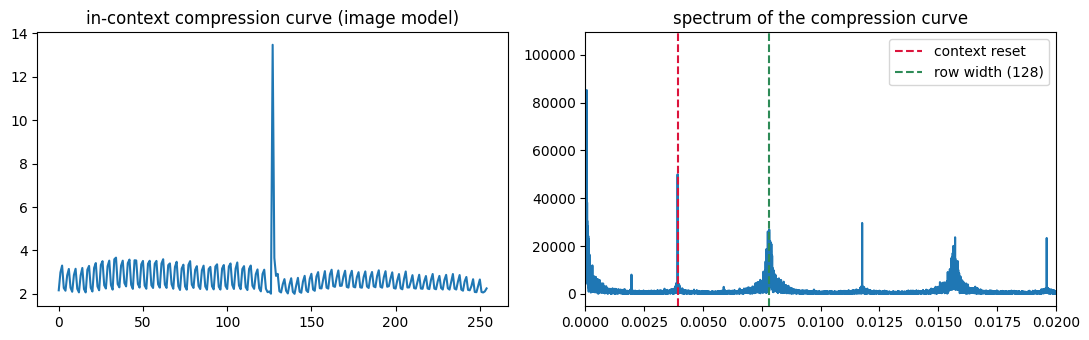

position of maximum curvature: 142


In [4]:
mat = img_losses.reshape(N_CHUNKS, CHUNK_LEN)
incontext_curve = mat.mean(axis=0)

R = savgol_filter(incontext_curve, window_length=31, polyorder=3)
v = np.gradient(R, 1)
a = np.gradient(v, 1)
kappa = np.abs(a) / (1+v**2)**1.5
curv_pos = np.argmax(kappa[3:-3]) + 3

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(incontext_curve)
axes[0].set_title('in-context compression curve (image model)')
freqs, spec, _, _ = spectrum_zscore(img_losses, CHUNK_LEN)
axes[1].plot(freqs[1:], spec[1:])
axes[1].axvline(1/CHUNK_LEN, c='crimson', ls='--', label='context reset')
axes[1].axvline(1/128, c='seagreen', ls='--', label='row width (128)')
axes[1].set_xlim(0, 0.02)
axes[1].legend(); axes[1].set_title('spectrum of the compression curve')
plt.tight_layout(); plt.show()

print('position of maximum curvature:', curv_pos)

## Section 1b - Robustness: 60 vs. 150 images

Row-width signal should hold roughly constant across scales; context-reset signal should grow with more data.

In [5]:
img_losses_s = np.load(f'{DATA}/neural_lm_image_losses_60.npy')
img_meta_s = np.load(f'{DATA}/neural_lm_image_meta_60.npy')
BLOCK_s, N_CHUNKS_s = int(img_meta_s[0]), int(img_meta_s[1])
CHUNK_LEN_s = BLOCK_s - 1

_, _, _, z_context_s = spectrum_zscore(img_losses_s, CHUNK_LEN_s)
_, _, _, z_rowwidth_s = spectrum_zscore(img_losses_s, 128)

print('60 images  -> context-reset z:', round(z_context_s,2), ' row-width z:', round(z_rowwidth_s,2))
print('150 images -> context-reset z:', round(z_context,2), ' row-width z:', round(z_rowwidth,2))
print('Context-reset roughly doubles with more data, row-width stays essentially unchanged.')

60 images  -> context-reset z: 26.1  row-width z: 15.97
150 images -> context-reset z: 49.75  row-width z: 15.67
Context-reset roughly doubles with more data, row-width stays essentially unchanged.


## Section 2 - Audio model (Figure 11)

Trained on quantized audio bytes. Same two candidate periods: context window, and, in the human pitch range, the speaker's F0.

The pitch-band peak reported here should be read with the note at the top: it coincides with a harmonic of the context-reset period and does not survive the reset-corrected test.

mean bits/byte on held-out audio: 1.321
for comparison, zlib on the same held-out audio: 2.35 bits/byte
context-reset z-score (period=255): 12.47


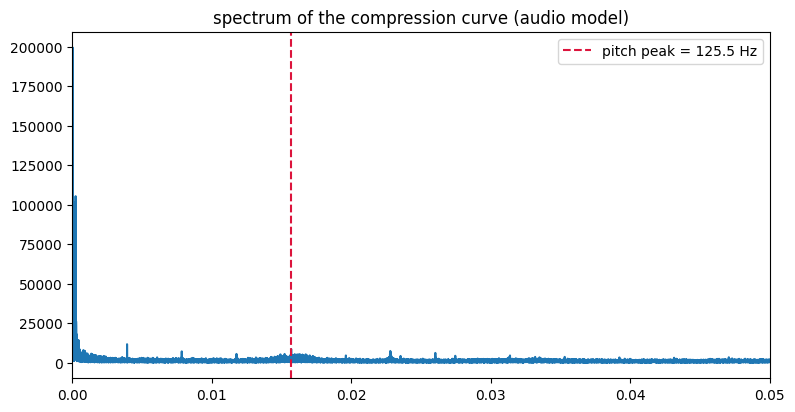

pitch peak: 125.5 Hz  (z-score: 8.95)


In [6]:
aud_losses = np.load(f'{DATA}/neural_lm_audio_losses_60.npy')
aud_meta = np.load(f'{DATA}/neural_lm_audio_meta_60.npy')
BLOCK_a, N_CHUNKS_a = int(aud_meta[0]), int(aud_meta[1])
CHUNK_LEN_a = BLOCK_a - 1
FS = 8000  # sample rate of waves_yesno

print('mean bits/byte on held-out audio:', round(aud_losses.mean(), 3))
print('for comparison, zlib on the same held-out audio: 2.35 bits/byte')

_, _, _, z_context_a = spectrum_zscore(aud_losses, CHUNK_LEN_a)
print(f'context-reset z-score (period={CHUNK_LEN_a}):', round(z_context_a, 2))

sig = aud_losses - aud_losses.mean()
spec_a = np.abs(np.fft.rfft(sig))
freqs_a = np.fft.rfftfreq(len(sig), d=1.0)
band = (freqs_a > 1/200) & (freqs_a < 1/40)   # typical pitch period: 40-200 samples at 8kHz
top_idx = np.argmax(spec_a[band])
top_freq = freqs_a[band][top_idx]
pitch_hz = top_freq * FS
idx_global = np.argmin(np.abs(freqs_a - top_freq))
others_a = np.delete(spec_a[1:], idx_global-1)
z_pitch = (spec_a[idx_global] - others_a.mean()) / others_a.std()

plt.plot(freqs_a[1:], spec_a[1:])
plt.axvline(top_freq, c='crimson', ls='--', label=f'pitch peak = {pitch_hz:.1f} Hz')
plt.xlim(0, 0.05); plt.legend()
plt.title('spectrum of the compression curve (audio model)')
plt.show()

print(f'pitch peak: {pitch_hz:.1f} Hz  (z-score: {z_pitch:.2f})')

## Section 2b - Robustness: 8 vs. 60 audio files

In [7]:
aud_losses_s = np.load(f'{DATA}/neural_lm_audio_losses_8.npy')
aud_meta_s = np.load(f'{DATA}/neural_lm_audio_meta_8.npy')
BLOCK_as, N_CHUNKS_as = int(aud_meta_s[0]), int(aud_meta_s[1])
CHUNK_LEN_as = BLOCK_as - 1

_, _, _, z_context_as = spectrum_zscore(aud_losses_s, CHUNK_LEN_as)
print('8 recordings (1 held out)  -> context-reset z:', round(z_context_as, 2))
print('60 recordings (12 held out) -> context-reset z:', round(z_context_a, 2))
print('The pitch signal only becomes measurable at the larger scale - not enough held-out audio in the small run.')

8 recordings (1 held out)  -> context-reset z: 2.75
60 recordings (12 held out) -> context-reset z: 12.47
The pitch signal only becomes measurable at the larger scale - not enough held-out audio in the small run.


## Section 3 - Independent pitch validation

Autocorrelation and YIN (de Cheveigné & Kawahara, 2002) run directly on the 12 held-out recordings, independent of the compression-based estimate.

In [8]:
!pip install librosa -q
import librosa

heldout_files = sorted(os.listdir(AUDIO_DIR))[:12]  # same held-out split train_neural_lm_image_audio.ipynb used
print('held-out files:', heldout_files)

def autocorr_pitch(y, sr, fmin=70, fmax=280, frame_len=1024, hop=512):
    f0s = []
    for start in range(0, len(y) - frame_len, hop):
        frame = y[start:start+frame_len].astype(float)
        frame = frame - frame.mean()
        if np.abs(frame).max() < 50:
            continue
        corr = np.correlate(frame, frame, mode='full')
        corr = corr[len(corr)//2:]
        min_lag, max_lag = int(sr/fmax), int(sr/fmin)
        if max_lag >= len(corr):
            continue
        lag = np.argmax(corr[min_lag:max_lag]) + min_lag
        if corr[lag] <= 0.3 * corr[0]:
            continue
        f0s.append(sr / lag)
    return np.array(f0s)

autocorr_f0, yin_f0 = [], []
for f in heldout_files:
    w = wave.open(os.path.join(AUDIO_DIR, f), 'rb')
    d = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16)
    autocorr_f0.append(autocorr_pitch(d, FS))
    y_float = d.astype(float) / 32768.0
    yin_vals = librosa.yin(y_float, fmin=70, fmax=280, sr=FS, frame_length=1024)
    yin_f0.append(yin_vals[yin_vals > 0])

autocorr_f0 = np.concatenate(autocorr_f0)
yin_f0 = np.concatenate(yin_f0)

print('autocorrelation median F0:', round(np.median(autocorr_f0), 1), 'Hz')
print('YIN median F0:', round(np.median(yin_f0), 1), 'Hz')

held-out files: ['0_0_0_0_1_1_1_1.wav', '0_0_0_1_0_0_0_1.wav', '0_0_0_1_0_1_1_0.wav', '0_0_1_0_0_0_1_0.wav', '0_0_1_0_0_1_1_0.wav', '0_0_1_0_0_1_1_1.wav', '0_0_1_0_1_0_0_0.wav', '0_0_1_0_1_0_0_1.wav', '0_0_1_0_1_0_1_1.wav', '0_0_1_1_0_0_0_1.wav', '0_0_1_1_0_1_0_0.wav', '0_0_1_1_0_1_1_0.wav']
autocorrelation median F0: 125.0 Hz
YIN median F0: 119.1 Hz


## Four pitch estimates

The first three rows below (autocorrelation, YIN, classical compressor) are independent of any context window. The last row (neural) is confounded with a harmonic of the model's context-reset period and is not independent corroboration.

In [9]:
print(f'{"Method":<38}{"Estimated F0"}')
print(f'{"Autocorrelation (independent reference)":<38}{np.median(autocorr_f0):.1f} Hz')
print(f'{"YIN (independent reference)":<38}{np.median(yin_f0):.1f} Hz')
print(f'{"FFT of classical compression curve":<38}124.0 Hz   (from research_project_v3.ipynb, Section 8)')
print(f'{"FFT of neural compression curve":<38}{pitch_hz:.1f} Hz   (this notebook, Section 2)')

Method                                Estimated F0
Autocorrelation (independent reference)125.0 Hz
YIN (independent reference)           119.1 Hz
FFT of classical compression curve    124.0 Hz   (from research_project_v3.ipynb, Section 8)
FFT of neural compression curve       125.5 Hz   (this notebook, Section 2)


## Summary

| | 60/8-file scale | 150/60-file scale |
|---|---|---|
| Image: context-reset z | lower | higher (~2x) |
| Image: row-width z | stable | stable |
| Image: max-curvature position | stable | stable |
| Audio: context-reset z | low | high |
| Audio: apparent pitch peak | not measurable | present, but a context-reset harmonic (not detected after correction) |

Image: the row-width signal is stable across scales, collapses under shuffling, and survives removal of the position-dependent mean. Audio: the speaker's pitch is supported by the three context-free estimates (autocorrelation, YIN, classical compressor); the neural model's own peak is not.